# Digital Advertising Budget Optimizer
## Notebook 04 — Apache Spark (PySpark)

**Goal:** compute the same KPIs with Apache Spark, validate them against Pandas, and explore the features
that make Spark the industry standard for big data: lazy evaluation, the query optimiser, in-memory caching,
SQL, and columnar file formats.

**Spark vs MapReduce in one line:** MapReduce writes to disk between every step and is programmed with low-level
map/reduce functions; Spark plans the whole job up front, keeps data in memory, and is programmed with DataFrames or SQL.

**Setup used here:** Spark in *local mode* (`local[*]`): one machine, one executor thread per CPU core.
The same code runs unchanged on a cluster.

**Outline**
1. Setup & data
2. Start Spark
3. Load data: CSV vs Parquet
4. Job 1: Platform KPIs (DataFrame API and SQL)
5. Under the hood: the execution plan
6. Job 2: Every breakdown + validation against Pandas
7. Optimisation: caching and grouping sets
8. CSV vs Parquet
9. Scaling: 10K → 10M rows
10. Findings

**Requires:** Notebooks 01 and 02 completed. Runtime ~5–8 min.

In [1]:
# ============================================================
# 1. Setup
# ============================================================
import os, sys, shutil, time, json, glob, subprocess
from pathlib import Path

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

PROJECT_NAME = "ad-budget-optimizer"
if IN_COLAB:
    drive.mount("/content/drive")
    DRIVE_DIR = Path("/content/drive/MyDrive") / PROJECT_NAME
    LOCAL_DIR = Path("/content") / PROJECT_NAME
else:
    DRIVE_DIR = LOCAL_DIR = Path.cwd() / PROJECT_NAME

SRC_DIR = DRIVE_DIR / "src"
FIG_DIR, REP_DIR, BENCH_DIR = (DRIVE_DIR / "outputs" / d for d in ("figures", "reports", "benchmarks"))
for d in (FIG_DIR, REP_DIR, BENCH_DIR):
    d.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(SRC_DIR))
assert (REP_DIR / "02_kpi_platform.csv").exists(), "Run Notebook 02 first (its results are used for validation)."

# Copy both formats of every dataset to fast local disk
SCALES = {"10k": 10_000, "100k": 100_000, "1m": 1_000_000, "10m": 10_000_000}
RAW_LOCAL = LOCAL_DIR / "data/raw"
for label in SCALES:
    for sub, name in (("csv", f"ads_{label}.csv"), ("parquet", f"ads_{label}")):
        src_p, dst_p = DRIVE_DIR / "data/raw" / sub / name, RAW_LOCAL / sub / name
        assert src_p.exists(), f"{src_p} missing. Run Notebook 01 first."
        if not dst_p.exists():
            dst_p.parent.mkdir(parents=True, exist_ok=True)
            t0 = time.time()
            (shutil.copytree if src_p.is_dir() else shutil.copy)(src_p, dst_p)
            print(f"Copied {sub}/{name} ({time.time() - t0:.0f}s)")
print("Data ready on local disk")

Mounted at /content/drive
Copied csv/ads_10k.csv (1s)
Copied parquet/ads_10k (1s)
Copied csv/ads_100k.csv (1s)
Copied parquet/ads_100k (1s)
Copied csv/ads_1m.csv (1s)
Copied parquet/ads_1m (2s)
Copied csv/ads_10m.csv (19s)
Copied parquet/ads_10m (13s)
Data ready on local disk


## 2. Start Spark
Colab usually has PySpark pre-installed; the cell installs it only if missing, and makes sure a compatible Java version is used
(Spark 3.x: Java 11/17, Spark 4.x: Java 17/21).

Key settings:
- `spark.driver.memory`: in local mode the driver does all the work, so it gets about half the machine's RAM
- `spark.sql.shuffle.partitions`: the default (200) suits big clusters; on a 2-core machine it just creates tiny tasks, so it is lowered to 4× the core count

In [2]:
# ============================================================
# 2. Install (if needed) and start Spark
# ============================================================
try:
    import pyspark
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyspark"], check=True)
    import pyspark
SPARK_MAJOR = int(pyspark.__version__.split(".")[0])

if IN_COLAB:
    ok_java = (17, 21) if SPARK_MAJOR >= 4 else (17, 11)
    jvm = [p for v in ok_java for p in sorted(glob.glob(f"/usr/lib/jvm/java-{v}-openjdk*"))]
    if not jvm:
        print("Installing Java 17 (~1 min)...")
        subprocess.run("apt-get update -qq && apt-get install -y -qq openjdk-17-jdk-headless > /dev/null",
                       shell=True, check=True)
        jvm = sorted(glob.glob("/usr/lib/jvm/java-17-openjdk*"))
    os.environ["JAVA_HOME"] = jvm[0]

from pyspark.sql import SparkSession, functions as F, types as T
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

try:
    import psutil
    ram_gb = psutil.virtual_memory().total / 1e9
except ImportError:
    ram_gb = 4
CORES = os.cpu_count()
DRIVER_MEM = f"{max(1, int(ram_gb * 0.5))}g"

spark = (SparkSession.builder
         .appName("AdBudgetOptimizer")
         .master("local[*]")
         .config("spark.driver.memory", DRIVER_MEM)
         .config("spark.sql.shuffle.partitions", str(CORES * 4))
         .config("spark.sql.execution.arrow.pyspark.enabled", "true")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

ENGINE = f"Spark {spark.version} local[{CORES}]"
print(f"{ENGINE} | driver memory {DRIVER_MEM} | Java: {os.environ.get('JAVA_HOME', 'system default')}")

Spark 4.0.4 local[2] | driver memory 6g | Java: /usr/lib/jvm/java-21-openjdk-amd64


## 3. Load data: CSV vs Parquet
For CSV, the schema is declared explicitly. Letting Spark infer it (`inferSchema=True`) costs an extra full pass over the file
and can guess types wrong. Parquet stores its schema inside the file, so nothing needs declaring.

Spark is **lazy**: `spark.read` only records *what* to read. Nothing is read until an **action** such as `count()` runs.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import importlib
from IPython.display import display, Markdown
import kpis, viz
importlib.reload(kpis); importlib.reload(viz)
viz.apply_style()
pd.set_option("display.width", 200)

SCHEMA = T.StructType([
    T.StructField("date", T.DateType()),
    T.StructField("campaign", T.StringType()),
    T.StructField("platform", T.StringType()),
    T.StructField("impressions", T.LongType()),
    T.StructField("clicks", T.LongType()),
    T.StructField("spend", T.DoubleType()),
    T.StructField("conversions", T.LongType()),
    T.StructField("revenue", T.DoubleType()),
    T.StructField("age", T.StringType()),
    T.StructField("gender", T.StringType()),
    T.StructField("city", T.StringType()),
    T.StructField("device", T.StringType()),
])


def read_ads(label, fmt="parquet"):
    if fmt == "csv":
        return spark.read.csv(str(RAW_LOCAL / "csv" / f"ads_{label}.csv"), header=True, schema=SCHEMA)
    return spark.read.parquet(str(RAW_LOCAL / "parquet" / f"ads_{label}"))


sdf = read_ads("10m", "parquet")            # lazy: nothing has been read yet
sdf.printSchema()
t0 = time.time()
n = sdf.count()                             # action: Spark now reads the data
print(f"{n:,} rows | {sdf.rdd.getNumPartitions()} partitions (Parquet) | "
      f"{read_ads('10m', 'csv').rdd.getNumPartitions()} partitions (CSV) | count took {time.time() - t0:.1f}s")
sdf.show(5, truncate=False)

root
 |-- date: date (nullable = true)
 |-- campaign: string (nullable = true)
 |-- platform: string (nullable = true)
 |-- impressions: long (nullable = true)
 |-- clicks: long (nullable = true)
 |-- spend: double (nullable = true)
 |-- conversions: long (nullable = true)
 |-- revenue: double (nullable = true)
 |-- age: string (nullable = true)
 |-- gender: string (nullable = true)
 |-- city: string (nullable = true)
 |-- device: string (nullable = true)

10,000,000 rows | 2 partitions (Parquet) | 7 partitions (CSV) | count took 5.1s
+----------+-----------------+---------+-----------+------+-------+-----------+--------+-----+------+----------+-------+
|date      |campaign         |platform |impressions|clicks|spend  |conversions|revenue |age  |gender|city      |device |
+----------+-----------------+---------+-----------+------+-------+-----------+--------+-----+------+----------+-------+
|2026-08-18|FB_Retargeting_01|Facebook |7670       |113   |1147.76|6          |9754.36 |35-44|Ma

## 4. Job 1: Platform KPIs
Spark computes the sums **and** the KPI ratios natively, with the same formulas as `kpis.py`
(ratio of totals; division by zero returns null instead of crashing).
The same result is then produced with plain SQL: Spark compiles both to the same execution plan.

In [4]:
def safe_div(a, b):
    return F.when(b != 0, a / b)


def spark_kpis(df, *by):
    """Group, sum base metrics, then add KPI ratio columns, all inside Spark."""
    agg = df.groupBy(*by).agg(*[F.sum(m).alias(m) for m in kpis.METRICS])
    return (agg
            .withColumn("CTR_%", 100 * safe_div(F.col("clicks"), F.col("impressions")))
            .withColumn("CPC", safe_div(F.col("spend"), F.col("clicks")))
            .withColumn("CVR_%", 100 * safe_div(F.col("conversions"), F.col("clicks")))
            .withColumn("CPA", safe_div(F.col("spend"), F.col("conversions")))
            .withColumn("ROAS", safe_div(F.col("revenue"), F.col("spend"))))


def to_pandas_kpis(sdf_kpis, index):
    """Collect the (small) result and add spend/revenue shares for display."""
    t = sdf_kpis.toPandas().set_index(index)
    t["spend_share_%"] = 100 * t.spend / t.spend.sum()
    t["revenue_share_%"] = 100 * t.revenue / t.revenue.sum()
    return t


t0 = time.time()
plat_spark = to_pandas_kpis(spark_kpis(sdf, "platform"), "platform").reindex(viz.PLATFORM_ORDER)
job1_s = time.time() - t0
plat_spark.to_csv(REP_DIR / "04_spark_kpi_platform.csv")
print(f"DataFrame API: platform KPIs on 10M rows in {job1_s:.1f}s")
display(kpis.view(plat_spark).sort_values("ROAS", ascending=False))

# The same question in SQL
sdf.createOrReplaceTempView("ads")
sql_result = spark.sql("""
    SELECT platform,
           SUM(spend)   / 1e6                AS spend_rs_m,
           SUM(revenue) / 1e6                AS revenue_rs_m,
           100 * SUM(clicks) / SUM(impressions) AS ctr_pct,
           SUM(spend) / SUM(conversions)     AS cpa,
           SUM(revenue) / SUM(spend)         AS roas
    FROM ads
    GROUP BY platform
    ORDER BY roas DESC
""").toPandas().set_index("platform").round(2)
print("Spark SQL:")
display(sql_result)
assert np.allclose(sql_result.roas, plat_spark.ROAS.round(2).loc[sql_result.index]), "SQL and DataFrame results differ"
print("DataFrame API and SQL agree ✅")

DataFrame API: platform KPIs on 10M rows in 7.6s


,Spend (Rs M),Revenue (Rs M),Spend share %,Revenue share %,CTR %,CPC (Rs),Conv. rate %,CPA (Rs),ROAS
platform,,,,,,,,,
Google,3832.29,17198.11,20.01,27.15,3.0,30.01,3.79,791.16,4.49
Instagram,4785.78,16894.96,24.99,26.68,1.0,18.00,1.90,946.97,3.53
Facebook,5746.80,18270.77,30.00,28.85,1.2,12.51,1.90,657.34,3.18
TikTok,2872.83,7509.36,15.00,11.86,0.8,8.75,0.95,918.90,2.61
YouTube,1916.08,3462.28,10.00,5.47,0.4,25.00,1.14,2196.01,1.81


Spark SQL:


,spend_rs_m,revenue_rs_m,ctr_pct,cpa,roas
platform,,,,,
Google,3832.29,17198.11,3.0,791.16,4.49
Instagram,4785.78,16894.96,1.0,946.97,3.53
Facebook,5746.80,18270.77,1.2,657.34,3.18
TikTok,2872.83,7509.36,0.8,918.90,2.61
YouTube,1916.08,3462.28,0.4,2196.01,1.81


DataFrame API and SQL agree ✅


## 5. Under the hood: the execution plan
`explain()` shows the plan Spark's **Catalyst optimiser** built. Three things are worth spotting:

- **`ReadSchema`** in the Parquet scan lists only the columns the query needs (*column pruning*): Spark never reads
  `campaign`, `age`, `city` … for this job. CSV cannot do this; every byte of every row must be parsed.
- **`HashAggregate` appears twice.** The first one is a *partial* aggregate inside each partition, the second merges them.
  This is Spark's built-in version of the in-mapper combining from Notebook 03, applied automatically.
- **`Exchange`** is the shuffle, the only point where data moves between partitions.

In [5]:
import re
plan = spark_kpis(sdf, "platform")._jdf.queryExecution().executedPlan().toString()
for line in plan.splitlines():
    line = line.strip()
    if "FileScan" in line:
        print(line[:60] + " ...")
        print("   " + re.search(r"ReadSchema: \S+", line).group(0))
    elif any(k in line for k in ("HashAggregate", "Exchange")):
        print(line[:150] + (" ..." if len(line) > 150 else ""))

+- HashAggregate(keys=[platform#2], functions=[sum(impressions#3L), sum(clicks#4L), sum(spend#5), sum(conversions#6L), sum(revenue#7)], output=[platfo ...
+- Exchange hashpartitioning(platform#2, 8), ENSURE_REQUIREMENTS, [plan_id=217]
+- HashAggregate(keys=[platform#2], functions=[partial_sum(impressions#3L), partial_sum(clicks#4L), partial_sum(spend#5), partial_sum(conversions#6L), ...
+- FileScan parquet [platform#2,impressions#3L,clicks#4L,spe ...
   ReadSchema: struct<platform:string,impressions:bigint,clicks:bigint,spend:double,conversions:bigint,revenue:d...


## 6. Job 2: Every breakdown + validation
Platform, campaign, age, gender, city, device and daily-by-platform, all computed in **one pass** with SQL
`GROUPING SETS` (Spark's equivalent of Notebook 03's multi-key mapper), then validated against Pandas.

In [6]:
DIMS = ["platform", "campaign", "age", "gender", "city", "device", "date"]
SETS = {"platform": ["platform"], "campaign": ["campaign"], "age": ["age"], "gender": ["gender"],
        "city": ["city"], "device": ["device"], "date|platform": ["date", "platform"]}


def grouping_id(cols):
    # Spark: grouping_id = bit per GROUP BY column, 1 = column not used in this grouping set
    return sum((0 if c in cols else 1) << (len(DIMS) - 1 - i) for i, c in enumerate(DIMS))


def all_breakdowns(view="ads"):
    sets_sql = ", ".join("(" + ", ".join(cols) + ")" for cols in SETS.values())
    sums = ", ".join(f"SUM({m}) AS {m}" for m in kpis.METRICS)
    return spark.sql(f"""
        SELECT {", ".join(DIMS)}, GROUPING_ID() AS gid, {sums}
        FROM {view}
        GROUP BY {", ".join(DIMS)} GROUPING SETS ({sets_sql})
    """)


t0 = time.time()
gs = all_breakdowns().toPandas()
job2_s = time.time() - t0
print(f"All 7 breakdowns ({len(gs):,} groups) from 10M rows in one pass: {job2_s:.1f}s")


def breakdown(name):
    cols = SETS[name]
    part = gs[gs.gid == grouping_id(cols)].copy()
    if name == "date|platform":
        part.index = pd.to_datetime(part.date).dt.strftime("%Y-%m-%d") + "|" + part.platform
    else:
        part.index = part[cols[0]].astype(str)
    return kpis.add_kpis(part[kpis.METRICS])


# Pandas reference results from Notebook 02
refs = {d: pd.read_csv(REP_DIR / f"02_kpi_{d}.csv", index_col=0)
        for d in ["platform", "campaign", "age", "gender", "city", "device"]}
daily_ref = pd.read_parquet(DRIVE_DIR / "data/processed/daily_platform_10m.parquet")
daily_ref.index = daily_ref.date.dt.strftime("%Y-%m-%d") + "|" + daily_ref.platform.astype(str)
refs["date|platform"] = kpis.add_kpis(daily_ref[kpis.METRICS])


def validate(name):
    ref = refs[name].copy()
    ref.index = ref.index.astype(str)
    sp = breakdown(name)
    same_keys = set(sp.index) == set(ref.index)
    sp = sp.reindex(ref.index)
    ints = ["impressions", "clicks", "conversions"]
    ints_exact = bool((sp[ints].values == ref[ints].values).all())
    money_diff = float(np.abs(sp[["spend", "revenue"]].values - ref[["spend", "revenue"]].values).max())
    money_ok = np.allclose(sp[["spend", "revenue"]], ref[["spend", "revenue"]], rtol=1e-9, atol=0.5)
    roas_ok = np.allclose(sp["ROAS"], ref["ROAS"], rtol=1e-9)
    return {"breakdown": name, "groups": len(ref), "same_groups": same_keys, "counts_exact": ints_exact,
            "max_money_diff_Rs": round(money_diff, 4), "roas_match": roas_ok,
            "status": "PASS" if same_keys and ints_exact and money_ok and roas_ok else "FAIL"}


validation = pd.DataFrame([validate(d) for d in SETS]).set_index("breakdown")
validation.to_csv(REP_DIR / "04_validation_vs_pandas.csv")
display(validation)
n_pass = (validation.status == "PASS").sum()
print(f"{n_pass}/{len(validation)} breakdowns match Pandas" + (" ✅" if n_pass == len(validation) else " ❌"))
for d in ["campaign", "age", "gender", "city", "device"]:
    breakdown(d).to_csv(REP_DIR / f"04_spark_kpi_{d}.csv")

All 7 breakdowns (1,890 groups) from 10M rows in one pass: 27.7s


,groups,same_groups,counts_exact,max_money_diff_Rs,roas_match,status
breakdown,,,,,,
platform,5,True,True,0.0005,True,PASS
campaign,40,True,True,0.0000,True,PASS
age,5,True,True,0.0002,True,PASS
gender,2,True,True,0.0007,True,PASS
city,10,True,True,0.0001,True,PASS
device,3,True,True,0.0028,True,PASS
date|platform,1825,True,True,0.0000,True,PASS


7/7 breakdowns match Pandas ✅


## 7. Optimisation: caching and grouping sets
Three ways to produce the same seven breakdowns from the 10M-row Parquet data:

| Strategy | What happens |
|---|---|
| 7 separate queries | Spark re-reads the files for every query |
| Cache + 7 queries | First query loads data into memory; the rest read from RAM |
| GROUPING SETS | One query, one read, all seven results |

,seconds
7 separate queries,32.41
Cache + 7 queries,83.01
GROUPING SETS (1 pass),24.32


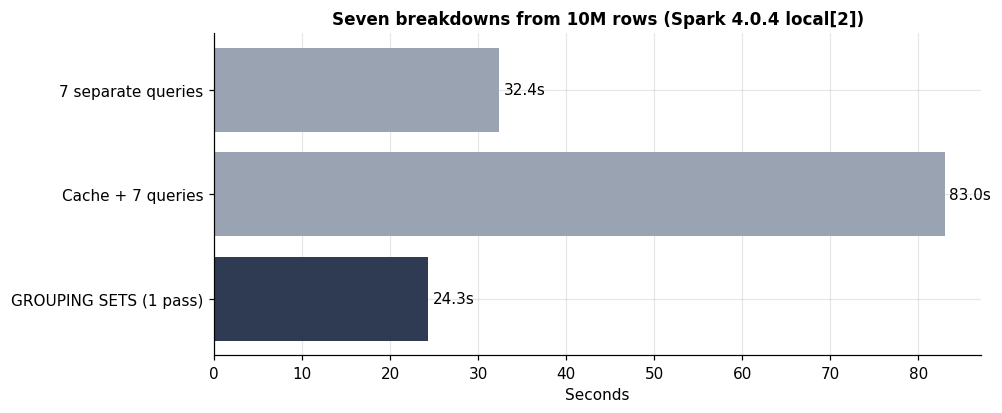

In [7]:
def seven_queries(df):
    for cols in SETS.values():
        df.groupBy(*cols).agg(*[F.sum(m) for m in kpis.METRICS]).collect()


strategies = {}

fresh = read_ads("10m")
t0 = time.time(); seven_queries(fresh); strategies["7 separate queries"] = time.time() - t0

cached = read_ads("10m").cache()
t0 = time.time(); cached.count(); seven_queries(cached); strategies["Cache + 7 queries"] = time.time() - t0
cached.unpersist()

read_ads("10m").createOrReplaceTempView("ads_fresh")
t0 = time.time(); all_breakdowns("ads_fresh").collect(); strategies["GROUPING SETS (1 pass)"] = time.time() - t0

opt = pd.Series(strategies, name="seconds").round(2).to_frame()
opt.to_csv(BENCH_DIR / "04_spark_optimisation.csv")
display(opt)

fig, ax = plt.subplots(figsize=(9, 3.8))
b = ax.barh(opt.index[::-1], opt.seconds[::-1], color=[viz.ACCENT if s == opt.seconds.min() else viz.NEUTRAL
                                                       for s in opt.seconds[::-1]])
ax.bar_label(b, fmt="%.1fs", padding=3)
ax.set_xlabel("Seconds")
ax.set_title(f"Seven breakdowns from 10M rows ({ENGINE})")
viz.save(fig, FIG_DIR, "04_spark_optimisation"); plt.show()

## 8. CSV vs Parquet
The same platform query on the same 10M rows, stored two ways.
Parquet is compressed, columnar and typed; CSV is plain text that must be parsed row by row.

In [8]:
def time_platform_job(label, fmt):
    df = read_ads(label, fmt)
    t0 = time.time()
    df.groupBy("platform").agg(*[F.sum(m) for m in kpis.METRICS]).collect()
    return time.time() - t0

time_platform_job("10k", "csv"); time_platform_job("10k", "parquet")   # warm-up (JVM start-up, JIT)

size_mb = {"CSV": (RAW_LOCAL / "csv/ads_10m.csv").stat().st_size / 1e6,
           "Parquet": sum(f.stat().st_size for f in (RAW_LOCAL / "parquet/ads_10m").glob("*.parquet")) / 1e6}
fmt_cmp = pd.DataFrame({"size_MB": size_mb,
                        "seconds": {"CSV": time_platform_job("10m", "csv"),
                                    "Parquet": time_platform_job("10m", "parquet")}}).round(1)
fmt_cmp.to_csv(BENCH_DIR / "04_spark_csv_vs_parquet.csv")
display(fmt_cmp)
print(f"Parquet is {fmt_cmp.size_MB.CSV / fmt_cmp.size_MB.Parquet:.1f}x smaller and "
      f"{fmt_cmp.seconds.CSV / fmt_cmp.seconds.Parquet:.1f}x faster for this query")

,size_MB,seconds
CSV,872.5,26.9
Parquet,180.1,3.0


Parquet is 4.8x smaller and 9.0x faster for this query


## 9. Scaling: 10K → 10M rows
The platform job on every dataset size, in both formats. Spark has a fixed cost per query (planning and scheduling tasks),
so small data shows little difference between sizes; the growth appears once real work dominates.

format,csv,parquet
dataset,,
10k,0.229,0.175
100k,0.598,0.225
1m,2.840,0.533
10m,25.400,3.064


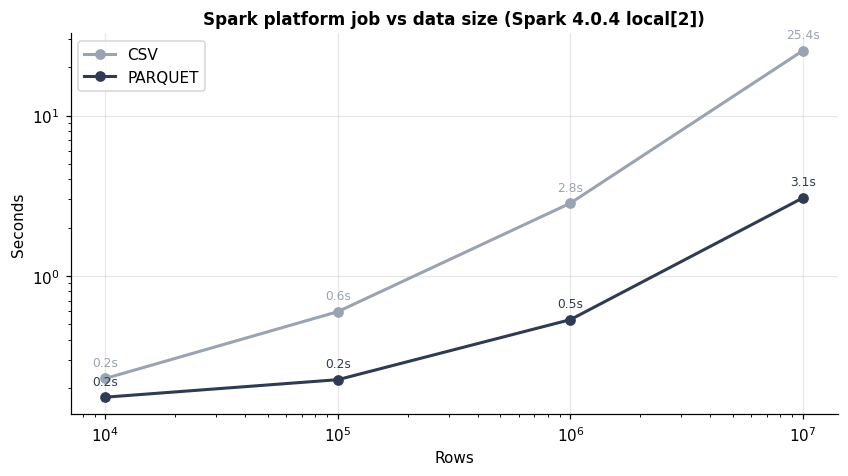

In [9]:
rows = []
for label, n in SCALES.items():
    for fmt in ("csv", "parquet"):
        rows.append({"dataset": label, "rows": n, "format": fmt,
                     "seconds": round(time_platform_job(label, fmt), 3), "engine": ENGINE})
scaling = pd.DataFrame(rows)
scaling["rows_per_sec"] = (scaling.rows / scaling.seconds).round(0)
scaling.to_csv(BENCH_DIR / "04_spark_scaling.csv", index=False)
display(scaling.pivot(index="dataset", columns="format", values="seconds").reindex(SCALES))

fig, ax = plt.subplots(figsize=(9, 4.5))
for fmt, color in (("csv", viz.NEUTRAL), ("parquet", viz.ACCENT)):
    s = scaling[scaling.format == fmt]
    ax.plot(s.rows, s.seconds, "o-", color=color, lw=2, label=fmt.upper())
    for _, r in s.iterrows():
        ax.annotate(f"{r.seconds:.1f}s", (r.rows, r.seconds), textcoords="offset points", xytext=(0, 8),
                    ha="center", fontsize=8, color=color)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Rows"); ax.set_ylabel("Seconds")
ax.set_title(f"Spark platform job vs data size ({ENGINE})")
ax.legend()
viz.save(fig, FIG_DIR, "04_spark_scaling"); plt.show()

## 10. Findings

In [10]:
pq_s = scaling[scaling.format == "parquet"].set_index("dataset")
best_strategy = opt.seconds.idxmin()
cache_note = ("Caching did not help here: the cache stores all 12 columns in memory, while each Parquet query "
              "reads only the few columns it needs. Caching pays off when data is reused many times or storage is slow."
              if opt.seconds["Cache + 7 queries"] > opt.seconds["7 separate queries"] else
              "Caching beat re-reading the files, because later queries were served from memory.")
findings = f"""
**Engine:** {ENGINE}

1. **Correctness:** {n_pass} of {len(validation)} breakdowns ({validation.groups.sum():,} groups) match Pandas,
   including the KPI ratios computed natively in Spark. DataFrame API and SQL give identical answers.
2. **Automatic optimisation:** Spark's planner applied partial aggregation (the equivalent of Notebook 03's
   hand-written in-mapper combining) and column pruning without any extra code.
3. **Reuse strategy:** for seven breakdowns, *{best_strategy}* was fastest ({opt.seconds.min():.1f}s vs
   {opt.seconds.max():.1f}s for the slowest approach). {cache_note}
4. **File format:** Parquet was {fmt_cmp.size_MB.CSV / fmt_cmp.size_MB.Parquet:.1f}x smaller than CSV and
   {fmt_cmp.seconds.CSV / fmt_cmp.seconds.Parquet:.1f}x faster to query.
5. **Scaling:** on Parquet, 10K rows took {pq_s.seconds['10k']:.2f}s and 10M rows {pq_s.seconds['10m']:.2f}s:
   {1000:,}x the data for {pq_s.seconds['10m'] / pq_s.seconds['10k']:.0f}x the time. Small queries are dominated by
   Spark's fixed per-query overhead.
"""
(REP_DIR / "04_findings.md").write_text(findings)
display(Markdown(findings))

spark.stop()


**Engine:** Spark 4.0.4 local[2]

1. **Correctness:** 7 of 7 breakdowns (1,890 groups) match Pandas,
   including the KPI ratios computed natively in Spark. DataFrame API and SQL give identical answers.
2. **Automatic optimisation:** Spark's planner applied partial aggregation (the equivalent of Notebook 03's
   hand-written in-mapper combining) and column pruning without any extra code.
3. **Reuse strategy:** for seven breakdowns, *GROUPING SETS (1 pass)* was fastest (24.3s vs
   83.0s for the slowest approach). Caching did not help here: the cache stores all 12 columns in memory, while each Parquet query reads only the few columns it needs. Caching pays off when data is reused many times or storage is slow.
4. **File format:** Parquet was 4.8x smaller than CSV and
   9.0x faster to query.
5. **Scaling:** on Parquet, 10K rows took 0.17s and 10M rows 3.06s:
   1,000x the data for 18x the time. Small queries are dominated by
   Spark's fixed per-query overhead.


## ✅ Notebook 04 complete

**Saved:** KPI tables and validation in `outputs/reports/04_*`, timings in `outputs/benchmarks/04_*`, charts in `outputs/figures/04_*`.

**Next: Notebook 05, Benchmark.** Pandas, MapReduce and Spark run the same job on all four dataset sizes,
in one session with repeated runs, for a fair head-to-head comparison.